# FoodJudgeBench — HUMMUS EDA (v2, corrected)

**What changed from v1**
- Rating `6.0` is **not a rating**: it marks authorship records. The data is now split into `reviews_clean` (ratings 1–5) and `authorship`, and *every* downstream number uses `reviews_clean`.
- Rating `2.5` is audited as a probable "reviewed without stars" placeholder.
- Recipe-side audit added: ingredient parsing (Python-literal, not JSON), nutrition plausibility, health-score direction, `normalization_comment`, duration, tags, duplicates, junk filter.
- Constraint "groundability" check (which dietary/time constraints can we label reliably?).
- Review-text audit (diet/health mentions, non-reviews, personal data).
- Profile-feasibility analysis (is there enough *evidence* per user to justify profile claims?).
- Cleaned tables are saved to `processed/`; thresholds live in one config cell.

**Things to verify against the HUMMUS README / `dataset_scripts.ipynb`** (flagged inline as `VERIFY`): meaning of rating 2.5, direction of the health scores, meaning of `normalization_comment`.

## 0. Setup and configuration

In [2]:
import ast
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
PROC_DIR = Path("processed")
PROC_DIR.mkdir(exist_ok=True)
SEED = 42

# ---- thresholds (change here, re-run) --------------------------------------
MIN_INGREDIENTS = 3            # recipe quality filter
MIN_STEPS = 2
MAX_DURATION_MIN = 24 * 60     # longer than a day = suspicious
MAX_CALORIES = 5000            # per serving
MIN_REVIEWS_PER_RECIPE = 3     # true reviews needed for the candidate catalog
LIKED_RATING = 4.0             # rating >= this counts as "liked"
PROFILE_MIN_REVIEWS = 20       # historical-profile candidate window (true reviews)
PROFILE_MAX_REVIEWS = 300      # exclude extreme power users
PROFILE_MIN_TEXT = 10          # reviews with text needed for evidence
# ----------------------------------------------------------------------------

SUMMARY = {}   # collected into processed/data_quality_summary.json at the end


def save_table(df, name):
    """Save to parquet, fall back to csv.gz if pyarrow is missing."""
    try:
        df.to_parquet(PROC_DIR / f"{name}.parquet", index=False)
        print(f"saved processed/{name}.parquet  {df.shape}")
    except Exception as e:  # noqa
        df.to_csv(PROC_DIR / f"{name}.csv.gz", index=False)
        print(f"saved processed/{name}.csv.gz  {df.shape}  (parquet failed: {type(e).__name__})")

## 1. Load

In [3]:
recipes = pd.read_csv(DATA_DIR / "pp_recipes.csv", low_memory=False).drop(columns=["Unnamed: 0"], errors="ignore")

# Only load the review columns we need (drops review_url / member_url).
reviews_raw = pd.read_csv(
    DATA_DIR / "pp_reviews.csv",
    low_memory=False,
    usecols=["member_id", "recipe_id", "new_member_id", "new_recipe_id",
             "rating", "text", "likes", "last_modified_date", "review_id"],
)

# Members: deliberately do NOT load member_name / avatar_url / urls (personal data, unused).
members = pd.read_csv(
    DATA_DIR / "pp_members.csv",
    low_memory=False,
    usecols=["member_id", "new_member_id", "member_description", "member_status",
             "member_avg_rating", "member_map_pin", "member_joined"],
)

for name, df in [("recipes", recipes), ("reviews (raw)", reviews_raw), ("members", members)]:
    print(f"{name:15s} shape={df.shape}  memory={df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

recipes         shape=(507335, 36)  memory=1,453 MB
reviews (raw)   shape=(1916424, 9)  memory=698 MB
members         shape=(299583, 7)  memory=69 MB


## 2. Dtypes and missingness (one combined report)

recipes


,dtype,non_null,missing,missing_pct
normalization_comment,str,14377,492958,97.166
tags,str,230649,276686,54.537
ingredient_food_kg_names,str,422250,85085,16.771
ingredient_food_kg_urls,str,422250,85085,16.771
serves,str,435937,71398,14.073
fsa_score,float64,491831,15504,3.056
description,str,497228,10107,1.992
duration,float64,499997,7338,1.446
who_score,float64,506208,1127,0.222
ingredients,str,507333,2,0.000


reviews_raw


,dtype,non_null,missing,missing_pct
text,str,1409706,506718,26.441
review_id,float64,1409914,506510,26.430
likes,float64,1409914,506510,26.430


members


,dtype,non_null,missing,missing_pct
member_avg_rating,float64,30784,268799,89.724
member_map_pin,str,32398,267185,89.186
member_description,str,39315,260268,86.877
member_status,str,69159,230424,76.915


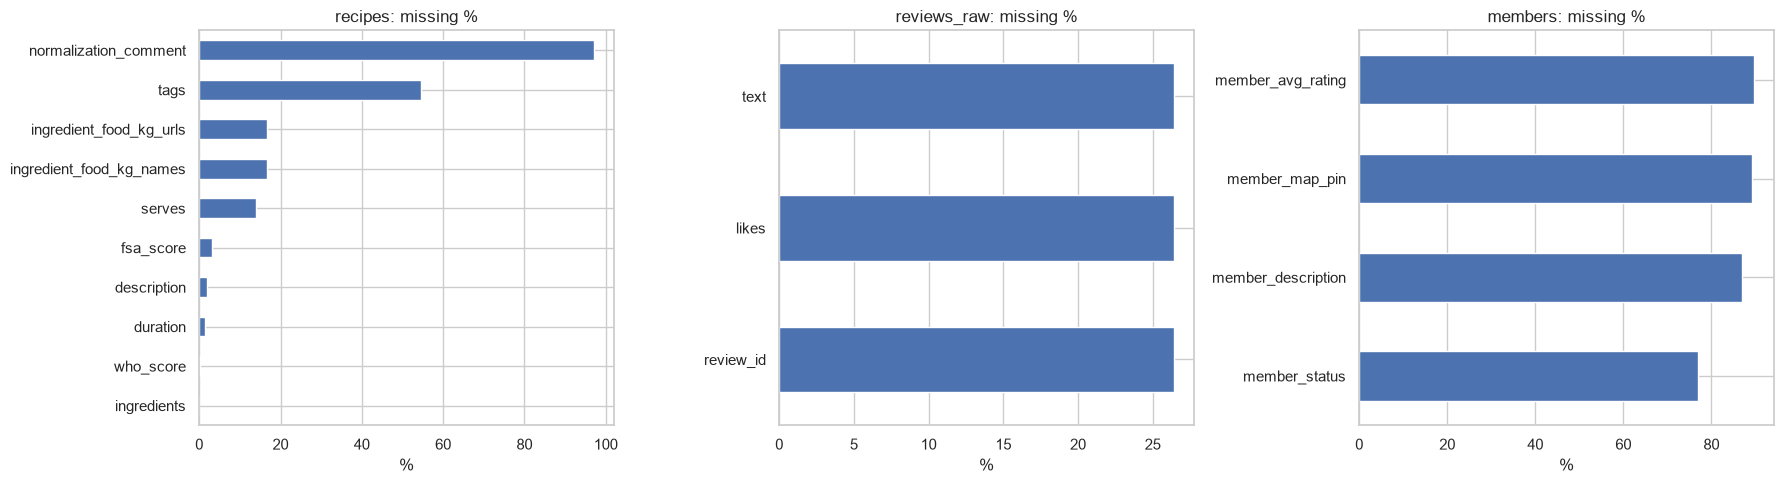

In [4]:
def missing_report(df):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
    })
    return out.sort_values("missing_pct", ascending=False)


reports = {"recipes": missing_report(recipes), "reviews_raw": missing_report(reviews_raw), "members": missing_report(members)}
for name, rep in reports.items():
    print("=" * 70, f"\n{name}\n", "=" * 70)
    display(rep[rep.missing > 0])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, rep) in zip(axes, reports.items()):
    r = rep[rep.missing_pct > 0]["missing_pct"].sort_values()
    if len(r):
        r.plot(kind="barh", ax=ax)
    ax.set_title(f"{name}: missing %")
    ax.set_xlabel("%")
plt.tight_layout()
plt.show()

## 3. ID audit and join integrity

Checks: key uniqueness, that raw↔`new_*` ID mappings agree between tables, and how many reviewing users are absent from `members`.

In [5]:
print("recipes: new_recipe_id unique:", recipes["new_recipe_id"].is_unique, "| recipe_id unique:", recipes["recipe_id"].is_unique)
print("members: new_member_id unique:", members["new_member_id"].is_unique)

# raw recipe_id <-> new_recipe_id mapping must agree between reviews and recipes
m = (reviews_raw[["recipe_id", "new_recipe_id"]].drop_duplicates()
     .merge(recipes[["recipe_id", "new_recipe_id"]], on="recipe_id", how="left", suffixes=("_rev", "_rec")))
print("recipe ID mapping mismatches (reviews vs recipes):", int((m["new_recipe_id_rev"] != m["new_recipe_id_rec"]).sum()))

# same for members
mm = (reviews_raw[["member_id", "new_member_id"]].drop_duplicates()
      .merge(members[["member_id", "new_member_id"]], on="member_id", how="inner", suffixes=("_rev", "_mem")))
print("member ID mapping mismatches (reviews vs members):", int((mm["new_member_id_rev"] != mm["new_member_id_mem"]).sum()))

review_users = set(reviews_raw["new_member_id"].unique())
member_ids = set(members["new_member_id"].unique())
missing_users = review_users - member_ids
share_rows_missing_user = (~reviews_raw["new_member_id"].isin(member_ids)).mean() * 100
print(f"\nreviewing users: {len(review_users):,} | members rows: {len(member_ids):,}")
print(f"reviewing users not in members: {len(missing_users):,}  ({share_rows_missing_user:.2f}% of interaction rows)")
print("recipes referenced by reviews but absent from recipes:", len(set(reviews_raw['new_recipe_id']) - set(recipes['new_recipe_id'])))

SUMMARY["users_in_reviews_not_in_members"] = len(missing_users)
SUMMARY["pct_rows_user_not_in_members"] = round(share_rows_missing_user, 3)

recipes: new_recipe_id unique: True | recipe_id unique: True
members: new_member_id unique: True
recipe ID mapping mismatches (reviews vs recipes): 0
member ID mapping mismatches (reviews vs members): 0

reviewing users: 302,412 | members rows: 299,583
reviewing users not in members: 2,829  (0.69% of interaction rows)
recipes referenced by reviews but absent from recipes: 0


## 4. The key fix: split **authorship** (rating = 6) from **reviews** (ratings 1–5)

In v1, `rating == 6.0` (506,510 rows) was treated as a rating. Those rows are exactly the ones with no `review_id` / `likes` / URLs, i.e. they are authorship records, not reviews.

In [6]:
print("rating value counts (raw):")
display(reviews_raw["rating"].value_counts().sort_index().to_frame("n"))

is_author = reviews_raw["rating"].eq(6.0)
no_review_id = reviews_raw["review_id"].isna()

print(f"rating == 6 rows:        {is_author.sum():,}")
print(f"review_id missing rows:  {no_review_id.sum():,}")
print("rating==6  <=>  review_id missing :", bool((is_author == no_review_id).all()))
assert (is_author == no_review_id).all(), "Sentinel hypothesis failed - inspect the mismatching rows before continuing"

# Does the user on a '6' row equal the recipe's author? (raw ids)
chk = (reviews_raw.loc[is_author, ["recipe_id", "member_id"]]
       .merge(recipes[["recipe_id", "author_id"]], on="recipe_id", how="left"))
author_match = (chk["member_id"] == chk["author_id"]).mean() * 100
print(f"rating==6 rows where member_id == recipe author_id: {author_match:.2f}%")

authorship = reviews_raw.loc[is_author, ["new_member_id", "new_recipe_id", "last_modified_date"]].copy()
reviews_clean = reviews_raw.loc[~is_author].copy()
reviews_clean["review_id"] = reviews_clean["review_id"].astype("int64")
del reviews_raw, chk, m, mm   # free memory

print(f"\nauthorship rows : {len(authorship):,}")
print(f"true reviews    : {len(reviews_clean):,}")
print(f"users with >=1 true review: {reviews_clean['new_member_id'].nunique():,}")
print(f"users appearing ONLY as authors: {len(set(authorship['new_member_id']) - set(reviews_clean['new_member_id'])):,}")

SUMMARY["authorship_rows"] = int(len(authorship))
SUMMARY["true_review_rows"] = int(len(reviews_clean))
SUMMARY["pct_rows_that_are_authorship"] = round(len(authorship) / (len(authorship) + len(reviews_clean)) * 100, 2)
SUMMARY["authorship_member_equals_author_pct"] = round(float(author_match), 2)
SUMMARY["users_with_true_review"] = int(reviews_clean["new_member_id"].nunique())

rating value counts (raw):


,n
rating,
1.000,16919
2.000,17778
2.500,76876
3.000,50564
4.000,229869
5.000,1017908
6.000,506510


rating == 6 rows:        506,510
review_id missing rows:  506,510
rating==6  <=>  review_id missing : True
rating==6 rows where member_id == recipe author_id: 100.00%

authorship rows : 506,510
true reviews    : 1,409,914
users with >=1 true review: 276,377
users appearing ONLY as authors: 26,035


## 5. Rating audit (true reviews only)

Points to check: heavy positive skew, and the odd value **2.5** (VERIFY: probably "reviewed without selecting stars").

,n,pct
rating,,
1.000,16919,1.200
2.000,17778,1.261
2.500,76876,5.453
3.000,50564,3.586
4.000,229869,16.304
5.000,1017908,72.196


count   1,409,914.000
mean            4.543
std             0.863
min             1.000
25%             4.000
50%             5.000
75%             5.000
max             5.000
Name: rating, dtype: float64


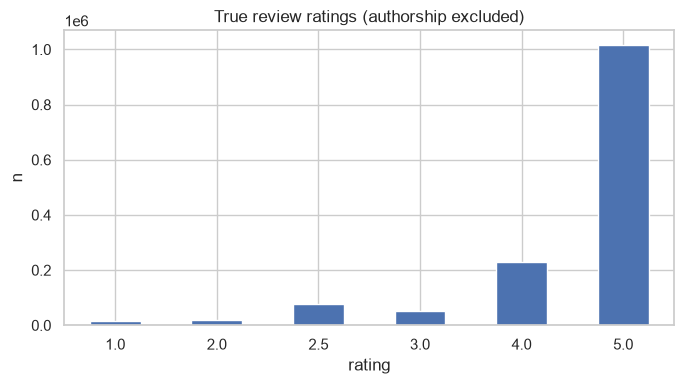


Rating 2.5 diagnostics:
  rows: 76,876
  with non-empty text: 100.0%   (others: 100.0%)
  with review_id:      100.0%
  -> if 2.5 rows have text/review_id like normal reviews, 2.5 = imputed 'no stars' value. Treat as unrated, NOT as a mild dislike.


In [7]:
star_counts = reviews_clean["rating"].value_counts().sort_index()
dist = star_counts.to_frame("n").assign(pct=lambda d: d["n"] / d["n"].sum() * 100)
display(dist)
print(reviews_clean["rating"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
star_counts.plot(kind="bar", ax=ax)
ax.set_title("True review ratings (authorship excluded)")
ax.set_xlabel("rating"); ax.set_ylabel("n")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# What is 2.5?
r25 = reviews_clean[reviews_clean["rating"] == 2.5]
others = reviews_clean[reviews_clean["rating"] != 2.5]
print("\nRating 2.5 diagnostics:")
print(f"  rows: {len(r25):,}")
print(f"  with non-empty text: {(r25['text'].fillna('').str.strip().str.len() > 0).mean() * 100:.1f}%   (others: {(others['text'].fillna('').str.strip().str.len() > 0).mean() * 100:.1f}%)")
print(f"  with review_id:      {r25['review_id'].notna().mean() * 100:.1f}%")
print("  -> if 2.5 rows have text/review_id like normal reviews, 2.5 = imputed 'no stars' value. Treat as unrated, NOT as a mild dislike.")

SUMMARY["rating_2_5_rows"] = int(len(r25))
SUMMARY["pct_5_star_of_true_reviews"] = round(float((reviews_clean["rating"] == 5).mean() * 100), 2)
SUMMARY["pct_le2_of_true_reviews"] = round(float((reviews_clean["rating"] <= 2).mean() * 100), 2)

# Explicit rating type column used from here on
reviews_clean["rating_type"] = np.where(reviews_clean["rating"] == 2.5, "no_stars(2.5)", "stars")
reviews_clean["liked"] = (reviews_clean["rating"] >= LIKED_RATING)

users with >=10 true reviews: 15,210
  share whose mean rating >= 4.8: 30.4%
  share with std < 0.3 (rate everything the same): 13.2%


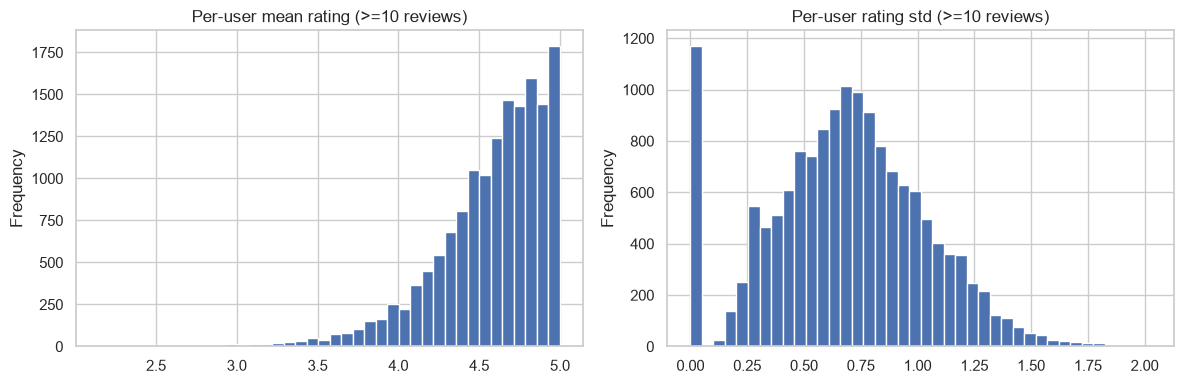

Takeaway: absolute ratings are a weak preference signal. Use rating relative to the user's own mean, a 'liked' flag, and review text.


In [8]:
# How much do individual users differ? (users with >= 10 true reviews)
ug = reviews_clean.groupby("new_member_id")["rating"].agg(n="count", mean="mean", std="std")
heavy = ug[ug["n"] >= 10]
print(f"users with >=10 true reviews: {len(heavy):,}")
print(f"  share whose mean rating >= 4.8: {(heavy['mean'] >= 4.8).mean() * 100:.1f}%")
print(f"  share with std < 0.3 (rate everything the same): {(heavy['std'] < 0.3).mean() * 100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
heavy["mean"].plot(kind="hist", bins=40, ax=ax[0], title="Per-user mean rating (>=10 reviews)")
heavy["std"].plot(kind="hist", bins=40, ax=ax[1], title="Per-user rating std (>=10 reviews)")
plt.tight_layout(); plt.show()
print("Takeaway: absolute ratings are a weak preference signal. Use rating relative to the user's own mean, a 'liked' flag, and review text.")

## 6. Review-text audit (true reviews only)

Beyond length: which reviews carry **evidence** usable for a profile (diet restrictions, health talk, household context), which are non-reviews, and is there personal data in the text.

In [9]:
txt = reviews_clean["text"].fillna("").astype(str).str.strip()
reviews_clean["has_text"] = txt.str.len() > 0
reviews_clean["text_len"] = txt.str.len()
reviews_clean["word_count"] = txt.str.count(r"\S+")

print(f"true reviews with text: {reviews_clean['has_text'].mean() * 100:.1f}%  ({reviews_clean['has_text'].sum():,})")
print("text length, among reviews WITH text:")
display(reviews_clean.loc[reviews_clean["has_text"], ["text_len", "word_count"]].describe(percentiles=[.1, .5, .9, .99]))

PATTERNS = {
    "mentions_restriction": r"\b(?:vegetarian|vegan|gluten|celiac|coeliac|lactose|dairy[- ]free|allerg\w*|nut[- ]free|kosher|halal|keto|low[- ]carb)\b",
    "mentions_health": r"\b(?:diabet\w*|blood sugar|cholesterol|low[- ]fat|low[- ]sodium|low[- ]calorie|calories|healthy|healthier|heart|weight loss|diet)\b",
    "mentions_household": r"\b(?:my kids?|my children|my son|my daughter|my husband|my wife|my family|toddler\w*|picky|my boyfriend|my girlfriend|my mom|my dad)\b",
    "mentions_modification": r"\b(?:i used|i substituted|i subbed|i added|i omitted|i left out|i replaced|i changed|instead of|i doubled|i halved)\b",
    "not_made_yet": r"\b(?:haven'?t (?:made|tried)|have not (?:made|tried)|going to (?:make|try)|can'?t wait to|plan to make|will be making|want to try|looks (?:good|great|delicious))\b",
}
has = reviews_clean["has_text"]
for col, pat in PATTERNS.items():
    reviews_clean[col] = False
    reviews_clean.loc[has, col] = txt[has].str.contains(pat, case=False, regex=True)

rates = pd.DataFrame({
    "n": {c: int(reviews_clean[c].sum()) for c in PATTERNS},
    "pct_of_reviews_with_text": {c: reviews_clean.loc[has, c].mean() * 100 for c in PATTERNS},
})
display(rates)

for c in ["mentions_restriction", "mentions_health", "mentions_household"]:
    print(f"\n--- random examples: {c} ---")
    ex = reviews_clean[reviews_clean[c]].sample(min(4, int(reviews_clean[c].sum())), random_state=SEED)
    for t in ex["text"]:
        print("  •", str(t)[:220].replace("\n", " "))

# personal-data scan
email_n = txt[has].str.contains(r"[\w.+-]+@[\w-]+\.[\w.-]+", regex=True).sum()
url_n = txt[has].str.contains(r"https?://|www\.", regex=True).sum()
print(f"\nreviews containing an email address: {email_n:,} | containing a URL: {url_n:,}  -> scrub/skip these before showing text to annotators or LLMs")

SUMMARY["pct_true_reviews_with_text"] = round(float(reviews_clean["has_text"].mean() * 100), 2)
SUMMARY["reviews_mentioning_restriction"] = int(reviews_clean["mentions_restriction"].sum())
SUMMARY["reviews_with_email"] = int(email_n)
SUMMARY["reviews_with_url"] = int(url_n)

true reviews with text: 100.0%  (1,409,703)
text length, among reviews WITH text:


,text_len,word_count
count,"1,409,703.000","1,409,703.000"
mean,275.233,51.471
std,195.999,36.924
min,1.000,1.000
10%,84.000,15.000
50%,234.000,44.000
90%,507.000,95.000
99%,960.000,181.000
max,"6,972.000","1,182.000"


,n,pct_of_reviews_with_text
mentions_restriction,28587,2.028
mentions_health,59032,4.188
mentions_household,165101,11.712
mentions_modification,450712,31.972
not_made_yet,58442,4.146



--- random examples: mentions_restriction ---
  • Very, very good!  Loved the sweetness derived from the prunes, but it surprisingly wasn't "pruney."  A perfect vegetarian "hearty" meal that will be a staple in my diet from now on (bring on the beano!).
  • Great recipe.  I did make two changes.  1) I left out the eggs because I have vegan friends; 2) I put in sweet red bell pepper relish instead of the pickle juice - this added some color and a unique pickled flavor.  If t
  • My husband is ga-ga over beef tongue, and he is greatly enamored with this recipe. The only change we made was to use soy creamer instead of heavy cream for the sauce because of a dairy allergy. That change probably made
  • I wanted a quick and easy chicken strips-type recipe to use with tenderloins and the tater tots I wanted on my way home today. This more than delivered! My roommate came back for seconds, even while attempting to make fu

--- random examples: mentions_health ---
  • I absolutely love this r

## 7. Temporal audit

The only timestamp is `last_modified_date` (when a review was last **edited**, not written). There is no `submit_date`. Use it for ordering at most, and check how much a time cutoff would cost.

unparseable review dates: 0
range: 2000-01-25 -> 2022-09-19


date,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
true_reviews,156,3911,27621,43877,59642,84977,112080,173517,203062,191784,129612,86193,66216,57635,35452,27636,21300,31812,24238,9072,11126,6720,2275
authorship,0,0,0,0,0,5019,3265,78417,99061,66743,51160,39606,32655,49887,22858,12714,7649,9163,8151,4179,8534,5199,2250


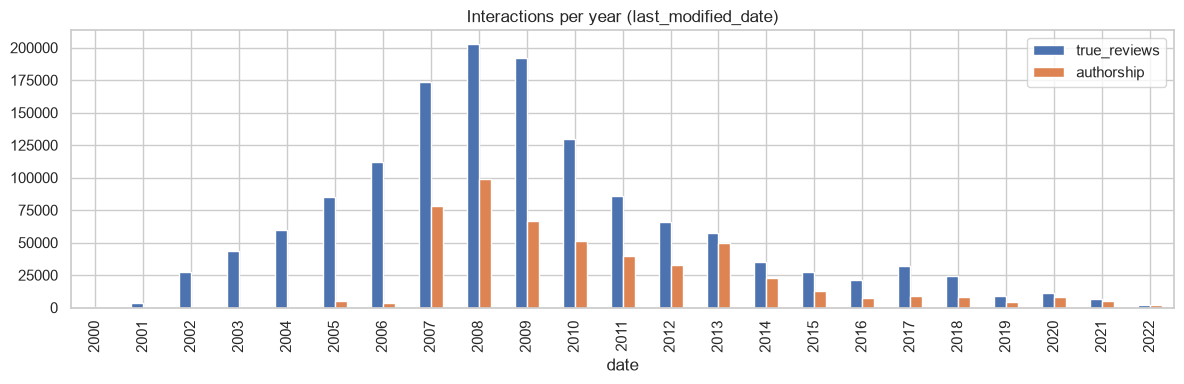

,cutoff,users_pre>=15_and_post>=3
0,2018-01-01,316
1,2019-01-01,219
2,2020-01-01,161


If these numbers are tiny, drop the temporal split (the Recall@K / NDCG@K check is the cuttable part of the project anyway).


In [10]:
reviews_clean["date"] = pd.to_datetime(reviews_clean["last_modified_date"], errors="coerce")
authorship["date"] = pd.to_datetime(authorship["last_modified_date"], errors="coerce")
print("unparseable review dates:", int(reviews_clean["date"].isna().sum()))
print("range:", reviews_clean["date"].min().date(), "->", reviews_clean["date"].max().date())

by_year = pd.DataFrame({
    "true_reviews": reviews_clean.groupby(reviews_clean["date"].dt.year).size(),
    "authorship": authorship.groupby(authorship["date"].dt.year).size(),
}).fillna(0).astype(int)
display(by_year.T)
by_year.plot(kind="bar", figsize=(12, 4), title="Interactions per year (last_modified_date)")
plt.tight_layout(); plt.show()

# Would a cutoff leave users with usable history on both sides?
CUTOFFS = ["2018-01-01", "2019-01-01", "2020-01-01"]
uc = reviews_clean.groupby("new_member_id").size()
elig = uc[uc >= PROFILE_MIN_REVIEWS].index
sub = reviews_clean[reviews_clean["new_member_id"].isin(elig)]
rows = []
for c in CUTOFFS:
    pre = (sub[sub["date"] < c].groupby("new_member_id").size())
    post = (sub[sub["date"] >= c].groupby("new_member_id").size())
    both = pd.concat([pre.rename("pre"), post.rename("post")], axis=1).fillna(0)
    rows.append({"cutoff": c, "users_pre>=15_and_post>=3": int(((both.pre >= 15) & (both.post >= 3)).sum())})
display(pd.DataFrame(rows))
print("If these numbers are tiny, drop the temporal split (the Recall@K / NDCG@K check is the cuttable part of the project anyway).")

## 8. User-history audit (the corrected version)

Side-by-side: what v1 would have reported (authorship rows counted as interactions) vs. true review counts.

In [11]:
true_counts = reviews_clean.groupby("new_member_id").size().rename("n_reviews")
raw_counts = pd.concat([reviews_clean["new_member_id"], authorship["new_member_id"]]).value_counts().rename("n_raw")

thresholds = [1, 2, 3, 5, 10, 20, 30, 50, 100, 300]
tab = pd.DataFrame({
    "min_interactions": thresholds,
    "users_v1_raw(incl. authorship)": [int((raw_counts >= t).sum()) for t in thresholds],
    "users_true_reviews": [int((true_counts >= t).sum()) for t in thresholds],
}).assign(pct_of_reviewers=lambda d: d["users_true_reviews"] / len(true_counts) * 100)
display(tab)
print(true_counts.describe(percentiles=[.5, .75, .9, .99]))
SUMMARY["users_true_reviews_ge_20"] = int((true_counts >= 20).sum())
SUMMARY["users_true_reviews_ge_10"] = int((true_counts >= 10).sum())

# power users: how many of their interactions are authorship?
top = pd.concat([true_counts, authorship.groupby("new_member_id").size().rename("n_authored")], axis=1).fillna(0)
display(top.sort_values("n_reviews", ascending=False).head(15).astype(int))
print(f"users with > {PROFILE_MAX_REVIEWS} true reviews (excluded from profile window): {(true_counts > PROFILE_MAX_REVIEWS).sum():,}")

# sparsity on true reviews
n_u, n_r, n_i = reviews_clean["new_member_id"].nunique(), reviews_clean["new_recipe_id"].nunique(), len(reviews_clean)
print(f"\nsparsity (true reviews): users={n_u:,} recipes={n_r:,} interactions={n_i:,} -> {100 * (1 - n_i / (n_u * n_r)):.5f}%")
dups = reviews_clean.groupby(["new_member_id", "new_recipe_id"]).size()
print("user-recipe pairs with >1 review:", int((dups > 1).sum()))

,min_interactions,users_v1_raw(incl. authorship),users_true_reviews,pct_of_reviewers
0,1,302412,276377,100.000
1,2,86426,72494,26.230
2,3,54858,45205,16.356
3,5,34133,27761,10.045
4,10,19016,15210,5.503
5,20,10497,8237,2.980
6,30,7414,5662,2.049
7,50,4614,3431,1.241
8,100,2376,1742,0.630
9,300,833,567,0.205


count   276,377.000
mean          5.101
std          53.115
min           1.000
50%           1.000
75%           2.000
90%           5.000
99%          62.000
max       8,844.000
Name: n_reviews, dtype: float64


,n_reviews,n_authored
new_member_id,,
53,8844,1006
612,6607,3299
115,5438,919
35,4700,529
677,4584,1622
71,3964,3925
152,3744,1941
72,3689,791
861,3592,767


users with > 300 true reviews (excluded from profile window): 564

sparsity (true reviews): users=276,377 recipes=271,240 interactions=1,409,914 -> 99.99812%
user-recipe pairs with >1 review: 0


## 9. Recipe audit

### 9.1 Parse `ingredients` and `tags` (both are stringified Python objects, **not** JSON)

In [12]:
def parse_ingredients(s):
    """'{group: [(name, qty), ...]}' -> list of lower-cased ingredient names (None if unparseable)."""
    if not isinstance(s, str):
        return None
    try:
        d = ast.literal_eval(s)
    except (ValueError, SyntaxError, MemoryError, RecursionError):
        return None
    if not isinstance(d, dict):
        return None
    names = []
    for items in d.values():
        for it in items:
            try:
                names.append(str(it[0]).lower().strip())
            except Exception:  # noqa
                continue
    return names


def parse_tags(s):
    if not isinstance(s, str):
        return None
    try:
        v = ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return None
    return [t for t in v if t] if isinstance(v, list) else None


print("example raw ingredients:", recipes["ingredients"].iloc[0][:200])
print("example parsed         :", parse_ingredients(recipes["ingredients"].iloc[0]))

recipes["ingredient_names"] = recipes["ingredients"].apply(parse_ingredients)     # ~1 min on full data
recipes["tags_list"] = recipes["tags"].apply(parse_tags)

recipes["n_ingredients"] = recipes["ingredient_names"].apply(lambda x: len(x) if x else 0)
fail = recipes["ingredient_names"].isna().sum()
print(f"\nunparseable ingredient strings: {fail:,}")
print(f"parsed length == ingredients_sizes: {(recipes['n_ingredients'] == recipes['ingredients_sizes']).mean() * 100:.1f}%")
recipes["ing_text"] = recipes["ingredient_names"].apply(lambda x: " ; ".join(x) if x else "")

example raw ingredients: {'': [('popcorn, popped', '12  time(s) cups '), ('dried cranberries', '1  time(s) cup '), ('whole almond', '0.5 time(s) cup '), ('butter', '0.5 time(s) cup '), ('brown sugar, packed', '0.5 time(s) cup
example parsed         : ['popcorn, popped', 'dried cranberries', 'whole almond', 'butter', 'brown sugar, packed', 'corn syrup (light color)', 'orange juice', 'vanilla', 'baking soda']

unparseable ingredient strings: 2
parsed length == ingredients_sizes: 100.0%


### 9.2 Tags

In [13]:
STRUCTURAL_TAGS = {"time-to-make", "course", "preparation", "main-ingredient", "cuisine", "occasion"}
tags_present = recipes["tags_list"].notna() & recipes["tags_list"].apply(lambda x: bool(x) if isinstance(x, list) else False)
print(f"recipes with usable tags: {tags_present.mean() * 100:.1f}%  -> absence of a tag is NOT evidence of absence of a property")

tag_counts = recipes["tags_list"].dropna().explode().value_counts()
display(tag_counts.head(40).to_frame("recipes"))
print("structural (uninformative) tags:", sorted(STRUCTURAL_TAGS))
SUMMARY["pct_recipes_with_usable_tags"] = round(float(tags_present.mean() * 100), 2)

recipes with usable tags: 45.4%  -> absence of a tag is NOT evidence of absence of a property


,recipes
tags_list,
preparation,229584
time-to-make,224383
course,217315
main-ingredient,170001
dietary,164578
easy,125716
occasion,113785
cuisine,90895
low-in-something,85474


structural (uninformative) tags: ['course', 'cuisine', 'main-ingredient', 'occasion', 'preparation', 'time-to-make']


### 9.3 Nutrition plausibility

Checks: zeros, extreme values, and an **energy consistency** test (4·protein + 4·carbs + 9·fat vs. reported calories).

,count,mean,std,min,1%,50%,99%,max,zero_pct
calories [cal],"507,335.000",482.942,"1,406.908",0.000,7.700,316.500,"3,625.996","612,854.600",0.581
caloriesFromFat [cal],"507,335.000",220.130,"1,013.810",0.000,0.000,123.000,"1,854.660","579,313.000",3.289
totalFat [g],"507,335.000",24.513,112.646,0.000,0.000,13.700,206.100,"64,368.100",2.153
saturatedFat [g],"507,335.000",9.514,47.097,0.000,0.000,4.700,84.200,"26,740.600",5.251
cholesterol [mg],"507,335.000",85.946,243.664,0.000,0.000,42.400,683.066,"89,892.000",21.065
sodium [mg],"507,335.000",761.278,"4,076.175",0.000,0.500,352.200,"5,503.064","1,246,921.100",0.568
totalCarbohydrate [g],"507,335.000",48.983,182.175,0.000,0.000,28.100,475.400,"108,294.600",1.079
dietaryFiber [g],"507,335.000",3.828,8.565,0.000,0.000,2.100,27.000,"3,012.000",5.143
sugars [g],"507,335.000",21.859,144.004,0.000,0.000,6.400,299.700,"90,682.300",2.246
protein [g],"507,335.000",17.417,39.810,0.000,0.000,9.100,95.000,"18,396.200",1.596


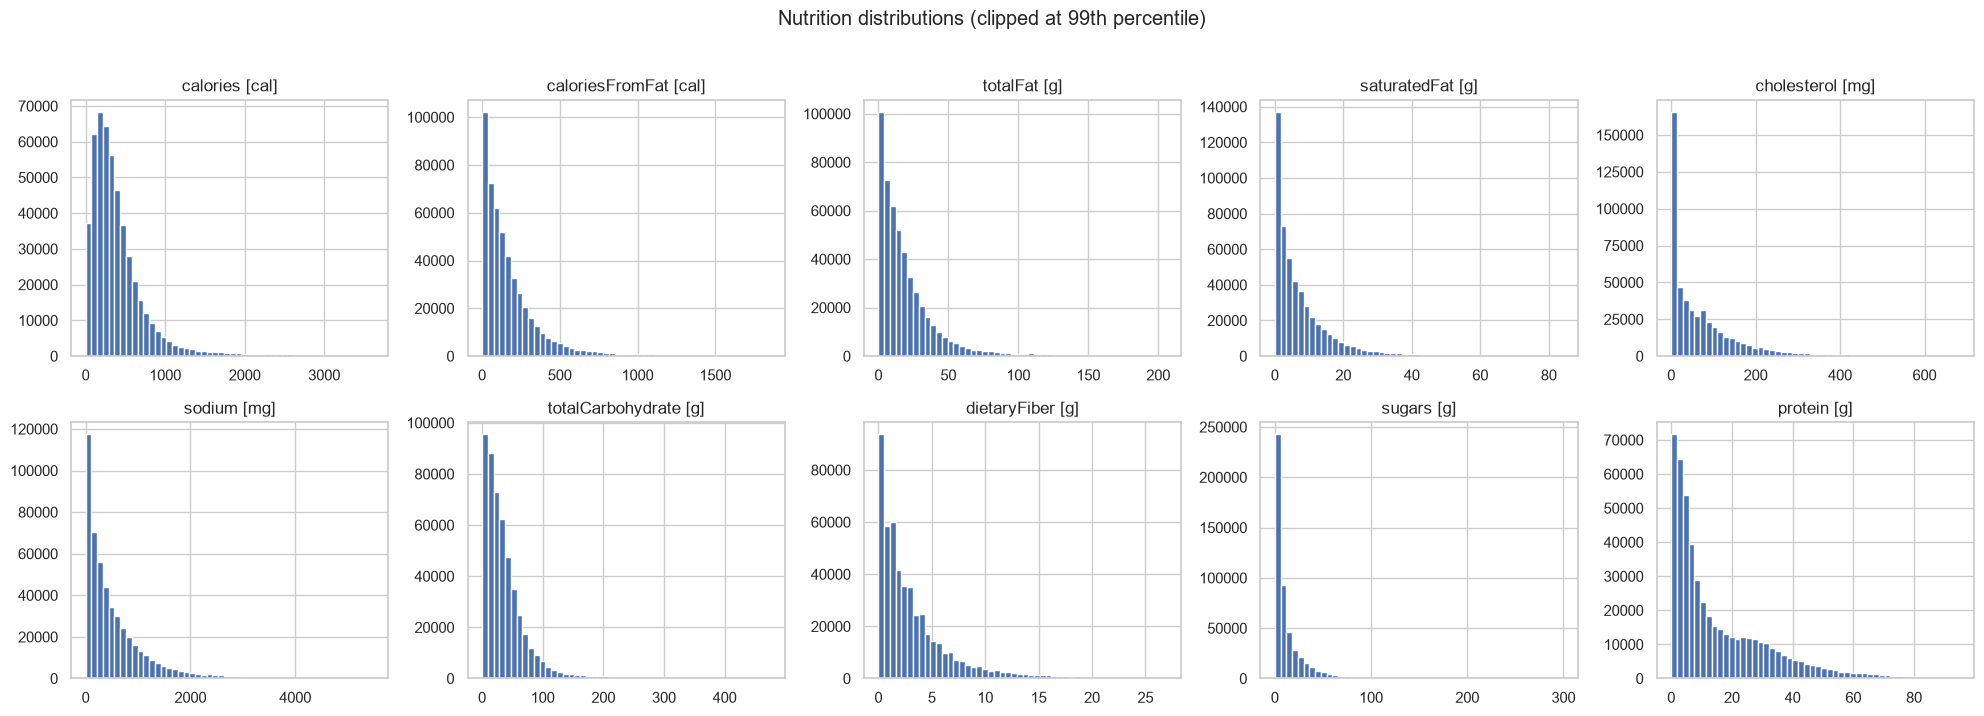


energy-consistent recipes (estimate within 0.7-1.3x of reported calories): 97.5%
calories == 0: 2,950 | calories > 5000: 2,501
saturated fat > total fat: 0 | sugars > carbs: 410


In [14]:
NUTR = ["calories [cal]", "caloriesFromFat [cal]", "totalFat [g]", "saturatedFat [g]", "cholesterol [mg]",
        "sodium [mg]", "totalCarbohydrate [g]", "dietaryFiber [g]", "sugars [g]", "protein [g]"]
desc = recipes[NUTR].describe(percentiles=[.01, .5, .99]).T
desc["zero_pct"] = [(recipes[c] == 0).mean() * 100 for c in NUTR]
display(desc)

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), NUTR):
    s = recipes[c]
    s[s <= s.quantile(0.99)].plot(kind="hist", bins=50, ax=ax, title=c)
    ax.set_ylabel("")
plt.suptitle("Nutrition distributions (clipped at 99th percentile)", y=1.02)
plt.tight_layout(); plt.show()

cal = recipes["calories [cal]"]
est = 4 * recipes["protein [g]"] + 4 * recipes["totalCarbohydrate [g]"] + 9 * recipes["totalFat [g]"]
ratio = (est / cal.replace(0, np.nan))
recipes["energy_consistent"] = ratio.between(0.7, 1.3)
print(f"\nenergy-consistent recipes (estimate within 0.7-1.3x of reported calories): {recipes['energy_consistent'].mean() * 100:.1f}%")
print(f"calories == 0: {(cal == 0).sum():,} | calories > {MAX_CALORIES}: {(cal > MAX_CALORIES).sum():,}")
print(f"saturated fat > total fat: {(recipes['saturatedFat [g]'] > recipes['totalFat [g]']).sum():,} | sugars > carbs: {(recipes['sugars [g]'] > recipes['totalCarbohydrate [g]']).sum():,}")

### 9.4 Health scores (`who_score`, `fsa_score`, `nutri_score`)

These are **normalized floats**, not 0–14 / 0–8 / A–E. VERIFY the direction in the README; the check below tests it empirically (a "higher = healthier" score should correlate negatively with sugar, sodium, saturated fat).

,count,mean,std,min,1%,50%,99%,max
who_score,"506,208.000",0.218,0.063,0.000,0.053,0.220,0.349,0.494
fsa_score,"491,831.000",0.454,0.283,0.000,0.000,0.375,1.000,1.000
nutri_score,"507,335.000",0.240,0.242,0.000,0.000,0.250,1.000,1.000


n unique values: {'who_score': 279808, 'fsa_score': 9, 'nutri_score': 5}
missing: {'who_score': 1127, 'fsa_score': 15504, 'nutri_score': 0}


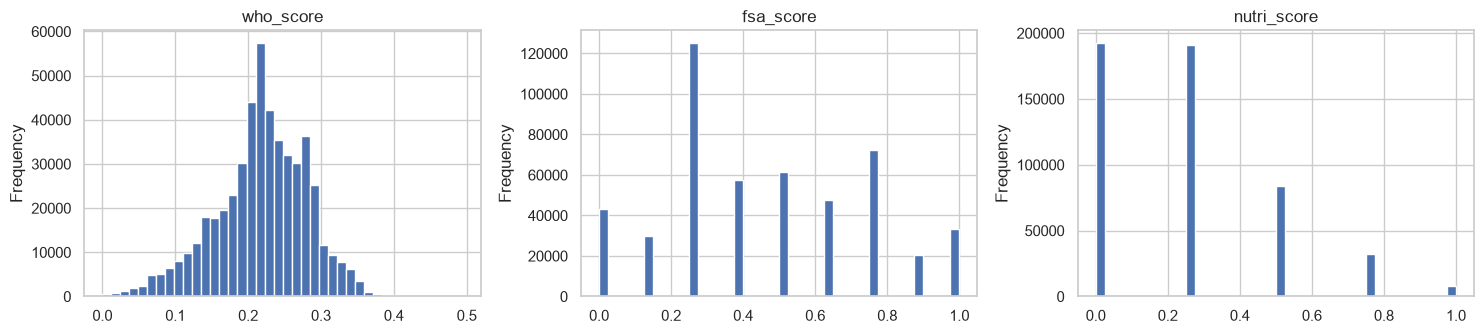


Spearman correlation between scores:


,who_score,fsa_score,nutri_score
who_score,1.000,0.699,0.674
fsa_score,0.699,1.000,0.832
nutri_score,0.674,0.832,1.000


Spearman correlation with nutrients (sample of 100k for speed):


,sugars [g],sodium [mg],saturatedFat [g],dietaryFiber [g],protein [g],calories [cal]
who_score,-0.361,-0.358,-0.535,0.133,-0.065,-0.362
fsa_score,-0.317,-0.416,-0.775,-0.061,-0.341,-0.597
nutri_score,-0.225,-0.476,-0.695,0.015,-0.391,-0.594


If scores correlate NEGATIVELY with sugar/sodium/sat-fat and POSITIVELY with fiber -> higher = healthier.


In [15]:
HS = ["who_score", "fsa_score", "nutri_score"]
display(recipes[HS].describe(percentiles=[.01, .5, .99]).T)
print("n unique values:", {c: int(recipes[c].nunique()) for c in HS})
print("missing:", {c: int(recipes[c].isna().sum()) for c in HS})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, HS):
    recipes[c].dropna().plot(kind="hist", bins=40, ax=ax, title=c)
plt.tight_layout(); plt.show()

print("\nSpearman correlation between scores:")
display(recipes[HS].corr(method="spearman"))

check_cols = ["sugars [g]", "sodium [mg]", "saturatedFat [g]", "dietaryFiber [g]", "protein [g]", "calories [cal]"]
print("Spearman correlation with nutrients (sample of 100k for speed):")
samp = recipes.sample(min(100_000, len(recipes)), random_state=SEED)
display(samp[HS + check_cols].corr(method="spearman").loc[HS, check_cols])
print("If scores correlate NEGATIVELY with sugar/sodium/sat-fat and POSITIVELY with fiber -> higher = healthier.")

### 9.5 `normalization_comment`, duration, rating columns

In [16]:
print("normalization_comment value counts:")
display(recipes["normalization_comment"].value_counts(dropna=False).head(5).to_frame("n"))
flagged = recipes["normalization_comment"].notna()
cmp = recipes.groupby(flagged)[["calories [cal]", "servingSize [g]", "servingsPerRecipe", "who_score"]].median()
cmp.index = ["not flagged", "flagged"]
display(cmp)
print("VERIFY meaning in dataset_scripts.ipynb. Default decision: exclude flagged recipes from the catalog (their nutrition was altered).")
SUMMARY["recipes_with_normalization_comment"] = int(flagged.sum())

print("\nduration (minutes):")
display(recipes["duration"].describe(percentiles=[.5, .9, .99, .999]).to_frame().T)
print(f"duration == 0: {(recipes['duration'] == 0).sum():,} | > {MAX_DURATION_MIN} min: {(recipes['duration'] > MAX_DURATION_MIN).sum():,} | missing: {recipes['duration'].isna().sum():,}")
for lim in [15, 30, 60]:
    tagged = recipes["tags"].fillna("").str.contains(f"'{lim}-minutes-or-less'", regex=False)
    if tagged.sum():
        print(f"tag '{lim}-minutes-or-less': {tagged.sum():,} recipes; duration <= {lim}: {(recipes.loc[tagged, 'duration'] <= lim).mean() * 100:.1f}%")

print("\naverage_rating == 0 only where number_of_ratings == 0?:",
      bool(((recipes["average_rating"] == 0) == (recipes["number_of_ratings"] == 0)).all()))
print("-> average_rating = 0 means 'no ratings', never average it in.")

normalization_comment value counts:


,n
normalization_comment,
NaN,492958
*,11398
**,2979


,calories [cal],servingSize [g],servingsPerRecipe,who_score
not flagged,315.000,224.000,4.000,0.221
flagged,390.600,64.000,5.000,0.163


VERIFY meaning in dataset_scripts.ipynb. Default decision: exclude flagged recipes from the catalog (their nutrition was altered).

duration (minutes):


,count,mean,std,min,50%,90%,99%,99.9%,max
duration,"499,997.000",64.794,95.036,1.000,40.000,130.000,500.000,870.000,"1,425.000"


duration == 0: 0 | > 1440 min: 0 | missing: 7,338
tag '15-minutes-or-less': 43,758 recipes; duration <= 15: 97.3%
tag '30-minutes-or-less': 54,859 recipes; duration <= 30: 99.9%
tag '60-minutes-or-less': 69,698 recipes; duration <= 60: 99.9%

average_rating == 0 only where number_of_ratings == 0?: False
-> average_rating = 0 means 'no ratings', never average it in.


### 9.6 Duplicates and junk

In [17]:
recipes["norm_title"] = recipes["title"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
recipes["ing_sig"] = recipes["ingredient_names"].apply(lambda l: "|".join(sorted(set(l))) if l else "")
recipes["dedup_key"] = pd.util.hash_pandas_object(recipes["norm_title"] + "##" + recipes["ing_sig"], index=False).values

print(f"unique titles: {recipes['title'].nunique():,} / {len(recipes):,}")
print(f"unique (title, ingredient-set) keys: {recipes['dedup_key'].nunique():,} / {len(recipes):,}")
print(f"unique food_kg_locator: {recipes['food_kg_locator'].nunique():,}")

print("\nsuspiciously thin recipes:")
print("  <3 ingredients      :", int((recipes['n_ingredients'] < MIN_INGREDIENTS).sum()))
print("  <2 steps            :", int((recipes['direction_size'] < MIN_STEPS).sum()))
print("  description ~ empty :", int((recipes['description'].fillna('').str.strip().str.len() <= 3).sum()))
display(recipes.loc[recipes["n_ingredients"] < MIN_INGREDIENTS, ["title", "ing_text", "direction_size"]].head(8))

unique titles: 425,969 / 507,335
unique (title, ingredient-set) keys: 506,492 / 507,335
unique food_kg_locator: 422,310

suspiciously thin recipes:
  <3 ingredients      : 5203
  <2 steps            : 22926
  description ~ empty : 11157


,title,ing_text,direction_size
194,Way Too Easy Cranberry/Orange Relish,ocean spray whole berry cranberry sauce ; larg...,5
270,Leapin' Lizard Leather,"very ripe chopped fruit (try kiwi, it's green!...",9
384,Bailey's Martini,baileys irish cream ; vodka,2
494,Cherry Cinnamon Cobbler,cherry pie filling ; container refrigerated ci...,8
579,Fruit Cubs,"ice, trays cold water, and fruit ; sugar (your...",2
614,Mexican Ranch Dressing,purchased ranch salad dressing ; taco seasoning,1
638,Godchild Cocktail,brandy ; amaretto,2
734,Zesty Carrots A.k.a. Clean out the Veggie Bin,"carrot, in bite-size pieces ; your favorite ba...",4


## 10. True review counts per recipe, quality flags, and the candidate catalog

In [18]:
rc = reviews_clean.groupby("new_recipe_id").agg(
    n_reviews=("rating", "size"),
    n_text_reviews=("has_text", "sum"),
    mean_true_rating=("rating", "mean"),
)
recipes = recipes.merge(rc, on="new_recipe_id", how="left")
recipes[["n_reviews", "n_text_reviews"]] = recipes[["n_reviews", "n_text_reviews"]].fillna(0).astype(int)

print(f"recipes with 0 true reviews (authorship only): {(recipes['n_reviews'] == 0).sum():,}")
print("n_reviews quantiles:", recipes["n_reviews"].quantile([.5, .75, .9, .99]).to_dict())
print(f"corr(scraped number_of_ratings, true review count): {recipes[['number_of_ratings', 'n_reviews']].corr(method='spearman').iloc[0, 1]:.3f}")

# keep the most-reviewed copy of each duplicate group
order = recipes.sort_values("n_reviews", ascending=False).index
is_dup = pd.Series(False, index=recipes.index)
is_dup.loc[order] = recipes.loc[order, "dedup_key"].duplicated(keep="first").values
recipes["is_duplicate"] = is_dup

conditions = [
    ("ingredients parsed, >= MIN_INGREDIENTS", recipes["n_ingredients"] >= MIN_INGREDIENTS),
    ("directions >= MIN_STEPS", recipes["direction_size"] >= MIN_STEPS),
    ("title length > 3", recipes["title"].str.len() > 3),
    ("calories in (0, MAX]", recipes["calories [cal]"].between(1, MAX_CALORIES)),
    ("energy-consistent nutrition", recipes["energy_consistent"]),
    ("not normalization-flagged", recipes["normalization_comment"].isna()),
    ("who_score & fsa_score present", recipes["who_score"].notna() & recipes["fsa_score"].notna()),
    ("duration present, 0 < d <= MAX", recipes["duration"].gt(0) & recipes["duration"].le(MAX_DURATION_MIN)),
    ("not a duplicate", ~recipes["is_duplicate"]),
]
mask = pd.Series(True, index=recipes.index)
wf = []
for label, cond in conditions:
    mask &= cond
    wf.append({"filter": label, "passes_alone": int(cond.sum()), "remaining_after": int(mask.sum())})
display(pd.DataFrame(wf))

recipes["quality_ok"] = mask
recipes["catalog_candidate"] = mask & (recipes["n_reviews"] >= MIN_REVIEWS_PER_RECIPE)
print(f"\nquality_ok recipes:        {recipes['quality_ok'].sum():,}")
print(f"catalog_candidate recipes: {recipes['catalog_candidate'].sum():,}  (quality_ok & >= {MIN_REVIEWS_PER_RECIPE} true reviews)")
print(f"  of which with usable tags: {(recipes['catalog_candidate'] & tags_present).sum():,}")
SUMMARY["recipes_quality_ok"] = int(recipes["quality_ok"].sum())
SUMMARY["recipes_catalog_candidate"] = int(recipes["catalog_candidate"].sum())

recipes with 0 true reviews (authorship only): 236,095
n_reviews quantiles: {0.5: 1.0, 0.75: 2.0, 0.9: 6.0, 0.99: 33.0}
corr(scraped number_of_ratings, true review count): 0.994


,filter,passes_alone,remaining_after
0,"ingredients parsed, >= MIN_INGREDIENTS",502132,502132
1,directions >= MIN_STEPS,484409,479885
2,title length > 3,507289,479855
3,"calories in (0, MAX]",501589,475342
4,energy-consistent nutrition,494660,467870
5,not normalization-flagged,492958,455575
6,who_score & fsa_score present,491831,455575
7,"duration present, 0 < d <= MAX",499997,449349
8,not a duplicate,506492,448652



quality_ok recipes:        448,652
catalog_candidate recipes: 102,317  (quality_ok & >= 3 true reviews)
  of which with usable tags: 86,915


## 11. Constraint groundability

Which constraints can we label *reliably* (needed for the "ignored constraint" diagnostic cases and the constraint-checking judge)? Rule-based labels from **ingredient names**; tags are used only as a cross-check because 54% of recipes have none. These rules are approximate on purpose — document them as such.

In [19]:
EXCLUDE_PHRASES = (r"coconut milk|almond milk|soy milk|soya milk|oat milk|rice milk|cashew milk|nut milk|peanut butter|almond butter|"
                   r"cocoa butter|cream of tartar|coconut cream|butternut|butter bean|nut butter|apple butter|seed butter|"
                   r"cream of coconut|gluten[- ]free|rice flour|almond flour|coconut flour|corn flour|chickpea flour|"
                   r"vegan butter|dairy[- ]free|vegetable broth|vegetable stock")
LISTS = {
    "meat_fish": r"\b(?:beef|pork|chicken|turkey|bacon|ham|hamburger|sausage|lamb|veal|duck|steak|meatball\w*|meat|fish|salmon|tuna|shrimp|prawns?|crab|lobster|anchov\w+|cod|tilapia|clams?|oysters?|scallops?|mussels?|pepperoni|salami|prosciutto|lard|bologna|venison|brisket|ribs?|sardines?)\b",
    "dairy": r"\b(?:milk|cheese|butter|cream|yogh?urt|whey|ghee|buttermilk|parmesan|mozzarella|cheddar|ricotta|custard)\b",
    "egg": r"\beggs?\b|\bmayonnaise\b",
    "honey": r"\bhoney\b",
    "gluten": r"\b(?:flour|wheat|bread|breadcrumbs?|pasta|noodles?|spaghetti|macaroni|couscous|barley|rye|bulgur|crackers?|tortillas?|soy sauce|beer|semolina|cake mix|biscuits?|pie crust|pastry|cereal|lasagna|orzo|panko)\b",
    "nuts": r"\b(?:peanuts?|almonds?|walnuts?|pecans?|cashews?|pistachios?|hazelnuts?|macadamia\w*|pine nuts?|nuts|nutella)\b",
}
clean_ing = recipes["ing_text"].str.replace(EXCLUDE_PHRASES, " ", regex=True)
for k, pat in LISTS.items():
    recipes[f"has_{k}"] = clean_ing.str.contains(pat, regex=True)

recipes["rule_vegetarian"] = ~recipes["has_meat_fish"]
recipes["rule_vegan"] = recipes["rule_vegetarian"] & ~recipes["has_dairy"] & ~recipes["has_egg"] & ~recipes["has_honey"]
recipes["rule_dairy_free"] = ~recipes["has_dairy"]
recipes["rule_gluten_free"] = ~recipes["has_gluten"]
recipes["rule_nut_free"] = ~recipes["has_nuts"]
for lim in [15, 30, 45, 60]:
    recipes[f"under_{lim}min"] = recipes["duration"].le(lim)

rule_cols = [c for c in recipes.columns if c.startswith("rule_") or c.startswith("under_")]
pool = recipes[recipes["catalog_candidate"]] if recipes["catalog_candidate"].any() else recipes[recipes["quality_ok"]]
display(pd.DataFrame({
    "all_recipes_pct": recipes[rule_cols].mean() * 100,
    "candidate_catalog_pct": pool[rule_cols].mean() * 100,
}))

# Cross-check with tags (only where tags exist)
has_tags = tags_present
rows = []
for tag, rule in [("vegetarian", "rule_vegetarian"), ("vegan", "rule_vegan"), ("gluten-free", "rule_gluten_free"),
                  ("dairy-free", "rule_dairy_free")]:
    tagged = has_tags & recipes["tags"].fillna("").str.contains(f"'{tag}'", regex=False)
    if tagged.sum() == 0:
        continue
    untagged = has_tags & ~tagged
    rows.append({"tag": tag, "n_tagged": int(tagged.sum()),
                 "rule_agrees_on_tagged_pct": recipes.loc[tagged, rule].mean() * 100,
                 "rule_true_on_untagged_pct": recipes.loc[untagged, rule].mean() * 100})
display(pd.DataFrame(rows))
print("rule_agrees_on_tagged_pct should be high (~90%+). If low, tighten the keyword lists before using these as ground truth.")
print("rule_true_on_untagged_pct being high shows why tags alone are NOT reliable for dietary constraints.")

,all_recipes_pct,candidate_catalog_pct
rule_vegetarian,61.449,59.473
rule_vegan,17.712,15.204
rule_dairy_free,40.338,37.801
rule_gluten_free,53.262,50.626
rule_nut_free,86.497,88.142
under_15min,18.026,15.940
under_30min,41.299,40.768
under_45min,59.078,59.881
under_60min,71.790,73.070


,tag,n_tagged,rule_agrees_on_tagged_pct,rule_true_on_untagged_pct
0,vegetarian,35599,95.795,54.684
1,vegan,9998,86.237,14.489
2,gluten-free,5732,84.037,52.656
3,dairy-free,194,85.052,40.243


rule_agrees_on_tagged_pct should be high (~90%+). If low, tighten the keyword lists before using these as ground truth.
rule_true_on_untagged_pct being high shows why tags alone are NOT reliable for dietary constraints.


## 12. Historical-profile feasibility

For users in the profile window: how much **evidence** do they have, and is there any health/time tendency that differs from the catalog base rate? A tendency counts only if it is clearly different from what you'd see in the catalog (z-score screen on liked recipes). This is the guard against "invented personalization".

In [20]:
cat = recipes[recipes["catalog_candidate"]] if recipes["catalog_candidate"].any() else recipes[recipes["quality_ok"]]
slim = recipes[["new_recipe_id", "calories [cal]", "sodium [mg]", "who_score", "fsa_score", "duration"]].rename(
    columns={"calories [cal]": "calories", "sodium [mg]": "sodium"})
slim["log_calories"] = np.log1p(slim["calories"])
slim["log_sodium"] = np.log1p(slim["sodium"])
slim["log_duration"] = np.log1p(slim["duration"])
METRICS = ["log_calories", "log_sodium", "who_score", "fsa_score", "log_duration"]
# Compare like with like: only recipes that pass the quality filter contribute to tendencies
# (junk recipes with absurd durations / nutrition would otherwise inflate every z-score).
slim.loc[~slim["new_recipe_id"].isin(recipes.loc[recipes["quality_ok"], "new_recipe_id"]), METRICS] = np.nan
base = slim[slim["new_recipe_id"].isin(cat["new_recipe_id"])][METRICS].agg(["mean", "std"])
display(base)

cand_users = true_counts[(true_counts >= PROFILE_MIN_REVIEWS) & (true_counts <= PROFILE_MAX_REVIEWS)].index
print(f"users in profile window [{PROFILE_MIN_REVIEWS}, {PROFILE_MAX_REVIEWS}] true reviews: {len(cand_users):,}")

rv = reviews_clean[reviews_clean["new_member_id"].isin(cand_users)].merge(slim, on="new_recipe_id", how="left")
g = rv.groupby("new_member_id")
us = g.agg(
    n_reviews=("rating", "size"), mean_rating=("rating", "mean"), rating_std=("rating", "std"),
    n_liked=("liked", "sum"), n_text=("has_text", "sum"),
    first_date=("date", "min"), last_date=("date", "max"),
    n_restriction=("mentions_restriction", "sum"), n_health=("mentions_health", "sum"),
    n_household=("mentions_household", "sum"), n_modification=("mentions_modification", "sum"),
)
us["span_years"] = (us["last_date"] - us["first_date"]).dt.days / 365.25

liked = rv[rv["liked"]]
for mcol in METRICS:
    mean_u = liked.groupby("new_member_id")[mcol].mean()
    cnt_u = liked.groupby("new_member_id")[mcol].count()
    
    # Force cnt_u to match the index of 'us' by filling unaligned users with 0
    cnt_u_aligned = cnt_u.reindex(us.index, fill_value=0)
    
    us[f"liked_{mcol}"] = mean_u
    us[f"z_{mcol}"] = (mean_u - base.loc["mean", mcol]) / (base.loc["std", mcol] / np.sqrt(cnt_u))
    
    # Use the perfectly aligned series for masking
    us.loc[cnt_u_aligned < 5, f"z_{mcol}"] = np.nan   # not enough liked recipes to say anything

display(us[["n_reviews", "n_liked", "n_text", "span_years", "n_restriction", "n_health", "n_household"]].describe(percentiles=[.5, .9]))

zc = [c for c in us.columns if c.startswith("z_")]
print("share of candidate users with a clear tendency (|z| >= 3) on each metric:")
display((us[zc].abs() >= 3).mean().to_frame("share_clear_tendency") * 100)

us["evidence_ok"] = (us["n_text"] >= PROFILE_MIN_TEXT) & (us["n_liked"] >= 10) & (us["span_years"] >= 1)
print(f"\nusers meeting evidence rule (>= {PROFILE_MIN_TEXT} text reviews, >= 10 liked, >= 1y span): {us['evidence_ok'].sum():,}")
print(f"  of those mentioning a dietary restriction at least once: {(us['evidence_ok'] & (us['n_restriction'] > 0)).sum():,}")
print(f"  of those mentioning health talk at least once:           {(us['evidence_ok'] & (us['n_health'] > 0)).sum():,}")
display(us[us["evidence_ok"]].sort_values("n_text", ascending=False).head(15)[
    ["n_reviews", "mean_rating", "n_liked", "n_text", "span_years", "n_restriction", "n_health", "n_household"]])

SUMMARY["profile_window_users"] = int(len(cand_users))
SUMMARY["profile_evidence_ok_users"] = int(us["evidence_ok"].sum())

,log_calories,log_sodium,who_score,fsa_score,log_duration
mean,5.701,5.729,0.220,0.450,3.713
std,0.889,1.450,0.060,0.275,0.931


users in profile window [20, 300] true reviews: 7,673


,n_reviews,n_liked,n_text,span_years,n_restriction,n_health,n_household
count,"7,673.000","7,673.000","7,673.000","7,673.000","7,673.000","7,673.000","7,673.000"
mean,59.533,53.957,59.533,6.044,1.060,2.323,7.501
std,52.698,48.699,52.698,3.683,2.921,3.786,9.716
min,20.000,0.000,19.000,0.003,0.000,0.000,0.000
50%,39.000,35.000,39.000,5.473,0.000,1.000,5.000
90%,129.000,118.000,129.000,11.230,3.000,6.000,17.000
max,300.000,294.000,300.000,20.140,93.000,51.000,228.000


share of candidate users with a clear tendency (|z| >= 3) on each metric:


,share_clear_tendency
z_log_calories,3.532
z_log_sodium,6.999
z_who_score,7.324
z_fsa_score,6.777
z_log_duration,7.702



users meeting evidence rule (>= 10 text reviews, >= 10 liked, >= 1y span): 7,353
  of those mentioning a dietary restriction at least once: 2,742
  of those mentioning health talk at least once:           4,814


,n_reviews,mean_rating,n_liked,n_text,span_years,n_restriction,n_health,n_household
new_member_id,,,,,,,,
9115,300,4.355,259,300,9.380,1,6,91
665,300,4.083,222,300,5.807,0,1,19
1205,300,4.465,281,300,16.526,10,7,55
4177,299,4.704,282,299,14.316,9,28,46
7150,298,4.826,289,298,2.500,0,9,3
3761,298,4.824,287,298,3.617,2,4,43
8383,297,4.958,294,297,6.467,19,42,0
2510,296,4.547,277,296,9.084,1,17,2
4485,296,4.399,275,296,13.900,14,15,38


## 13. Save cleaned outputs

In [21]:
# Reviews: true reviews only, no URLs / names. Authorship kept separately.
rev_cols = ["new_member_id", "new_recipe_id", "rating", "rating_type", "liked", "text", "has_text", "date",
            "mentions_restriction", "mentions_health", "mentions_household", "mentions_modification", "not_made_yet"]
save_table(reviews_clean[rev_cols], "reviews_clean")
save_table(authorship[["new_member_id", "new_recipe_id", "date"]], "authorship")

rec_cols = (["new_recipe_id", "title", "description", "duration", "tags_list", "ingredient_names", "n_ingredients", "direction_size",
             "average_rating", "number_of_ratings", "n_reviews", "n_text_reviews", "mean_true_rating", "servingsPerRecipe", "servingSize [g]"]
            + NUTR + HS
            + ["energy_consistent", "is_duplicate", "quality_ok", "catalog_candidate"]
            + [c for c in recipes.columns if c.startswith(("has_", "rule_", "under_"))])
save_table(recipes[rec_cols], "recipes_flagged")
save_table(us.reset_index(), "user_profile_candidates")

with open(PROC_DIR / "data_quality_summary.json", "w") as f:
    json.dump(SUMMARY, f, indent=2)
print(json.dumps(SUMMARY, indent=2))

saved processed/reviews_clean.csv.gz  (1409914, 13)  (parquet failed: ImportError)
saved processed/authorship.csv.gz  (506510, 3)  (parquet failed: ImportError)
saved processed/recipes_flagged.csv.gz  (507335, 47)  (parquet failed: ImportError)
saved processed/user_profile_candidates.csv.gz  (7673, 24)  (parquet failed: ImportError)
{
  "users_in_reviews_not_in_members": 2829,
  "pct_rows_user_not_in_members": 0.69,
  "authorship_rows": 506510,
  "true_review_rows": 1409914,
  "pct_rows_that_are_authorship": 26.43,
  "authorship_member_equals_author_pct": 100.0,
  "users_with_true_review": 276377,
  "rating_2_5_rows": 76876,
  "pct_5_star_of_true_reviews": 72.2,
  "pct_le2_of_true_reviews": 2.46,
  "pct_true_reviews_with_text": 99.99,
  "reviews_mentioning_restriction": 28587,
  "reviews_with_email": 106,
  "reviews_with_url": 3071,
  "users_true_reviews_ge_20": 8237,
  "users_true_reviews_ge_10": 15210,
  "pct_recipes_with_usable_tags": 45.44,
  "recipes_with_normalization_comment": 1

## 14. Findings to copy into the data-quality note

Fill these from the printed outputs above (the numbers are also in `processed/data_quality_summary.json`):

1. **Rating 6 = authorship.** N rows (X% of interactions) were removed from the review table; all rating statistics use true reviews only.
2. **Rating 2.5** = N rows, treated as "reviewed without stars" (VERIFY), excluded from like/dislike logic.
3. **Rating skew:** X% of true reviews are 5 stars, Y% are ≤2 → negatives must come from text, ratings are used relative to each user.
4. **Users:** N true reviewers; N with ≥20 true reviews (v1 over-reported this because authorship rows counted); N in the profile window; N pass the evidence rule.
5. **Members table:** N reviewing users missing; table is mostly empty and contains personal data → not used.
6. **Timestamps:** only `last_modified_date` (edit time); cutoff split decision: ___.
7. **Recipes:** N junk/thin, N duplicates, N normalization-flagged, N inconsistent nutrition → N `quality_ok`, N `catalog_candidate`.
8. **Constraints:** rule-based labels from ingredients (tags are 54% missing); agreement with tags on tagged recipes: ___%.
9. **Text:** X% of true reviews have text; N mention a dietary restriction; N contain emails/URLs (scrub before annotation).